# NOMe-HiC cortex QC plots (snakemake pipeline)

QC summary and histograms for cells processed under this snakemake workdir, using the same logic as [`s1.ipynb`](../../scnomehic_paper/s1/s1.ipynb) (`summarize_cellline_qc_from_data`).

**Inputs (per cell):**
- `04.alignment_snakemake/{prefix}.summary.txt.gz` — Hi-C alignment stats
- `07.bistools_snakemake/qc/{prefix}/*.calmd.trinuc_methy.chrM.txt.gz` and `chr19.txt` — methylation QC
- `07.bistools_snakemake/methylation/{prefix}/*.cyt.filtered.sort.{GCH,HCG}.6plus2.bed.gz` — site counts

**Outputs:** `QC/` tables, `figures/cortex_summary.pdf`, `QC/cortex_passed.txt`, `figures/cortex_summary.pdf`, `figures/cortex_summary_p99.pdf` (p99 cap), `figures/cortex_summary_by_batch.pdf` (full), `figures/cortex_summary_by_batch_p99.pdf` (always p99), `figures/cortex_summary_by_batch_p99_if_outlier.pdf` (p99 only if outliers)

By default all cells with completed QC outputs are included. Set `BATCHES = ['batch2', 'batch3', 'batch4']` in the discovery cell to match the paper's mixed-cortex subset.

**Methylation matrices:** `QC/methylation_matrices/methylation_matrix_{GCH,HCG}_250kb.tsv.gz`


In [1]:
import gzip
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from matplotlib.backends.backend_pdf import PdfPages
from tqdm.auto import tqdm

WORKDIR = Path('/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake')
os.chdir(WORKDIR)

ALIGN_DIR = WORKDIR / '04.alignment_snakemake'
QC_DIR = WORKDIR / '07.bistools_snakemake' / 'qc'
METH_DIR = WORKDIR / '07.bistools_snakemake' / 'methylation'
OUT_QC = WORKDIR / 'QC'
OUT_FIG = WORKDIR / 'figures'
OUT_QC.mkdir(exist_ok=True)
OUT_FIG.mkdir(exist_ok=True)

with open('config.yaml') as f:
    CFG = yaml.safe_load(f)

THRESHOLDS = {
    'fragnum_threshold': CFG['fragnum_threshold'],
    'noncpg_threshold': CFG['noncpg_threshold'],
    'GCH_threshold': CFG['GCH_threshold'],
    'HCG_threshold': CFG['HCG_threshold'],
    'cis1kbnum_threshold': CFG['cis1kbnum_threshold'],
}
print('Workdir:', WORKDIR)
print('QC thresholds:', THRESHOLDS)

Workdir: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake
QC thresholds: {'fragnum_threshold': 100000, 'noncpg_threshold': 5, 'GCH_threshold': 1000000, 'HCG_threshold': 150000, 'cis1kbnum_threshold': 2000}


In [2]:
def summarize_cellline_qc_from_data(
    prefixes,
    gch_hcg_df,
    chrm_df,
    chr19_df,
    summary_files,
    dataset_label='cortex',
    output_file=None,
    summary_pdf=None,
    utilized_cell_output=None,
    fragnum_threshold=500000,
    noncpg_threshold=3,
    GCH_threshold=1_000_000,
    HCG_threshold=80_000,
    cis1kbnum_threshold=3000,
    show_inline=False,
    summary_pdf_p99=None,
    clip_percentile_p99=99,
    clip_only_if_outlier=True,
):
    """
    Summarize QC metrics from in-memory data for NOMe-HiC cortex analysis.

    Parameters
    ----------
    prefixes : list[str]
        List of sample prefixes (e.g., ['batch1.sc10.ACTTGA', ...])
    gch_hcg_df : pd.DataFrame
        DataFrame with index=sample, columns=['GCH', 'HCG']
    chrm_df : pd.DataFrame
        DataFrame with index=sample, columns=['noncpg', 'endo', 'exo']
    summary_files : list[str]
        List of paths to alignment summary files (same order as prefixes)
    dataset_label : str
        Dataset name label (default 'cortex')
    output_file, summary_pdf, utilized_cell_output : str or None
        Optional output paths for saving results
    *_threshold : numeric
        Filtering thresholds
    show_inline : bool
        If True, display plots inline in Jupyter

    Returns
    -------
    df_all : pd.DataFrame
        All QC metrics
    df_passed : pd.DataFrame
        QC-passing subset
    """

    def plot_hist(
        df,
        column,
        title,
        xlabel,
        pdf=None,
        threshold=None,
        clip_percentile=None,
        clip_only_if_outlier=False,
    ):
        plt.figure(figsize=(8, 5))
        subset = df[column].dropna()
        if subset.empty:
            plt.close()
            return

        plot_vals = subset
        title_use = title
        bins = 50

        if clip_percentile is not None:
            x_hi = np.percentile(subset, clip_percentile)
            n_above = int((subset > x_hi).sum())
            apply_clip = n_above > 0 if clip_only_if_outlier else True
            if apply_clip:
                plot_vals = subset[subset <= x_hi]
                x_lo = plot_vals.min()
                bins = np.linspace(x_lo, x_hi, 51)
                if n_above > 0:
                    title_use = (
                        f"{title} (x ≤ p{clip_percentile:.0f}={x_hi:.4g}; "
                        f"{n_above} above)"
                    )

        plt.hist(
            plot_vals,
            bins=bins,
            alpha=0.7,
            color='steelblue',
            edgecolor='black',
        )
        if threshold is not None:
            plt.axvline(
                threshold,
                color='red',
                linestyle='--',
                linewidth=1.5,
                label='threshold',
            )
        plt.title(title_use)
        plt.xlabel(xlabel)
        plt.ylabel('Frequency')
        if threshold is not None:
            plt.legend()
        if pdf:
            pdf.savefig()
        if show_inline:
            plt.show()
        plt.close()
    chrm_df.columns = ['noncpg_chrM','endo_chrM','exo_chrM']
    # --- Parse summaries ---
    all_entries = []
    for prefix, summ_path in tqdm(zip(prefixes, summary_files), total=len(prefixes), desc="Parsing QC summaries"):
        entry = {"prefix": prefix, "dataset": dataset_label}
        try:
            align_df = pd.read_csv(summ_path, sep='\t', header=None)
            entry.update({
                'uniquemap': float(align_df[align_df[0]=='UniqMapped:'][2].values[0].strip('%')),
                'mapq30rate': float(align_df[align_df[0]=='UniqMappedMapQ30:'][2].values[0].strip('%')),
                'mapq30num': int(align_df[align_df[0]=='UniqMappedMapQ30:'][1].values[0]),
                'fragnum': int(align_df[align_df[0]=='TotalFragments:'][1].values[0]),
                'cisnum':int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCis:'][1].values[0]), 
                'cis1kbnum': int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCisMore1kb:'][1].values[0]),
                'cis10kbnum': int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCisMore10kb:'][1].values[0]),
                'transnum': int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrTrans:'][1].values[0]),
                'cis1kbrate': float(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCisMore1kb:'][2].values[0].strip('%')),
                'transrate': float(align_df[align_df[0]=='UniqMappedMapQ30NoPcrTrans:'][2].values[0].strip('%')),
            })
        except Exception:
            entry.update({k: np.nan for k in [
                'uniquemap','mapq30rate','mapq30num','fragnum','cisnum','cis1kbnum','cis10kbnum','transnum','cis1kbrate','transrate'
            ]})

        # Add methylation and GCH/HCG data
        if prefix in chrm_df.index:
            entry.update(chrm_df.loc[prefix].to_dict())
        else:
            entry.update({'noncpg_chrM': np.nan, 'endo_chrM': np.nan, 'exo_chrM': np.nan})

        if prefix in chr19_df.index:
            entry.update(chr19_df.loc[prefix].to_dict())
        else:
            entry.update({'noncpg': np.nan, 'endo': np.nan, 'exo': np.nan})

        if prefix in gch_hcg_df.index:
            entry.update(gch_hcg_df.loc[prefix].to_dict())
        else:
            entry.update({'GCH': np.nan, 'HCG': np.nan})

        all_entries.append(entry)

    df = pd.DataFrame(all_entries)

    # --- Save summary table ---
    if output_file:
        df.to_csv(output_file, sep='\t', index=False)
        print(f"✅ Saved summary table: {output_file}")

    # --- Plot histograms ---
    plot_columns = [
        ('fragnum', 'Raw fragment number', '# of fragments'),
        ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
        ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
        ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
        ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'), 
        ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
        ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
        ('cis10kbnum', 'Cis interactions >10kb Hi-C', '# of cis interactions'),
        ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
        ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
        ('noncpg_chrM', 'Non-CpG methylation rate', '% methylation'),
        ('endo_chrM', 'Endogenous methylation rate', '% methylation'),
        ('exo_chrM', 'Exogenous methylation rate', '% methylation'),
        ('noncpg', 'Non-CpG methylation rate', '% methylation'),
        ('endo', 'Endogenous methylation rate', '% methylation'),
        ('exo', 'Exogenous methylation rate', '% methylation'),
        ('GCH', 'Number of GCH sites', 'Number of sites'),
        ('HCG', 'Number of HCG sites', 'Number of sites')
    ]
    thresholds = {
        'fragnum': fragnum_threshold,
        'noncpg': noncpg_threshold,
        'noncpg_chrM': noncpg_threshold,
        'GCH': GCH_threshold,
        'HCG': HCG_threshold,
        'cis1kbnum': cis1kbnum_threshold,
    }

    pdf_jobs = []
    if summary_pdf:
        pdf_jobs.append((summary_pdf, None, False, False))
    if summary_pdf_p99:
        pdf_jobs.append(
            (summary_pdf_p99, clip_percentile_p99, True, clip_only_if_outlier)
        )

    for pdf_path, clip_p, show, clip_if_out in pdf_jobs:
        with PdfPages(pdf_path) as pdf:
            for col, title, xlabel in plot_columns:
                plot_hist(
                    df,
                    col,
                    title,
                    xlabel,
                    pdf,
                    thresholds.get(col),
                    clip_percentile=clip_p,
                    clip_only_if_outlier=clip_if_out,
                )
        print(f"✅ Saved summary PDF: {pdf_path}")

    if show_inline and not pdf_jobs:
        for col, title, xlabel in plot_columns:
            plot_hist(df, col, title, xlabel, None, thresholds.get(col))
    elif show_inline and pdf_jobs:
        for col, title, xlabel in plot_columns:
            plot_hist(
                df,
                col,
                title,
                xlabel,
                None,
                thresholds.get(col),
                clip_percentile=clip_percentile_p99 if summary_pdf_p99 else None,
                clip_only_if_outlier=clip_only_if_outlier,
            )

    # --- Filtering ---
    df_filtered = df[
        (df['fragnum'] > fragnum_threshold) &
        (df['noncpg'] < noncpg_threshold) &
        (df['noncpg_chrM'] < noncpg_threshold) &
        (df['GCH'] > GCH_threshold) &
        (df['HCG'] > HCG_threshold) &
        (df['cis1kbnum'] > cis1kbnum_threshold)
    ]

    if utilized_cell_output:
        df_filtered['prefix'].to_csv(utilized_cell_output, index=False, header=False)
        print(f"✅ Saved passing cell list: {utilized_cell_output}")

    print(f"✅ {len(df_filtered)}/{len(df)} cells passed QC thresholds")
    return df, df_filtered


In [3]:
TRINUC_SUFFIX_CHRM = '.calmd.trinuc_methy.chrM.txt.gz'
TRINUC_SUFFIX_CHR19 = '.calmd.trinuc_methy.chr19.txt.gz'
BED_MIDDLE = '.cyt.filtered.sort.'


def _trinuc_percent(path, trinuc):
  """Return methylation % for trinuc (e.g. ACT) from a trinuc_methy file."""
  df = pd.read_csv(path, sep='\t', header=None, names=['trinuc', 'count', 'percent'])
  vals = df.loc[df['trinuc'] == f'{trinuc}:', 'percent']
  if len(vals) == 0:
    return np.nan
  return float(str(vals.iloc[0]).strip('%'))


def build_trinuc_table(prefixes, suffix):
  rows = []
  for prefix in tqdm(prefixes, desc=f'trinuc {suffix}'):
    path = QC_DIR / prefix / f'{prefix}{suffix}'
    if not path.exists():
      rows.append([prefix, np.nan, np.nan, np.nan])
      continue
    rows.append([
      prefix,
      _trinuc_percent(path, 'ACT'),
      _trinuc_percent(path, 'ACG'),
      _trinuc_percent(path, 'GCT'),
    ])
  df = pd.DataFrame(rows, columns=['sample', 'noncpg', 'endo', 'exo'])
  return df.set_index('sample')


def _count_bed_gz(path):
  if not path.exists():
    return np.nan
  with gzip.open(path, 'rt') as f:
    return sum(1 for _ in f)


def build_gch_hcg_table(prefixes):
  rows = []
  for prefix in tqdm(prefixes, desc='GCH/HCG counts'):
    meth_cell = METH_DIR / prefix
    gch = meth_cell / f'{prefix}{BED_MIDDLE}GCH.6plus2.bed.gz'
    hcg = meth_cell / f'{prefix}{BED_MIDDLE}HCG.6plus2.bed.gz'
    rows.append([prefix, _count_bed_gz(gch), _count_bed_gz(hcg)])
  df = pd.DataFrame(rows, columns=['sample', 'GCH', 'HCG'])
  return df.set_index('sample')


def discover_prefixes(qc_dir=QC_DIR, align_dir=ALIGN_DIR):
  """Sample folders under 07.bistools_snakemake/qc/ that have a completed
  trinuc QC file + an alignment summary file (in 04 or in qc/<prefix>/).

  Older batch2 cells: summary lives at qc/<prefix>/<prefix>.summary.txt.gz.
  Newer scNH cells:  summary only at 04.alignment_snakemake/<prefix>.summary.txt.gz.
  Both layouts are accepted."""
  prefixes = []
  for p in sorted(qc_dir.iterdir()):
    if not p.is_dir():
      continue
    has_trinuc = (p / f'{p.name}{TRINUC_SUFFIX_CHR19}').exists()
    has_summary = (
      (p / f'{p.name}.summary.txt.gz').exists()
      or (align_dir / f'{p.name}.summary.txt.gz').exists()
    )
    if has_trinuc and has_summary:
      prefixes.append(p.name)
  return prefixes


In [4]:
# Discover cells with completed bis-QC outputs
all_prefixes = discover_prefixes()
print(f'Found {len(all_prefixes)} cells with QC outputs')

# Drop samples whose input fastq was effectively empty (TotalFragments < min).
# These add noise to the QC plots and waste I/O in the slow bed-counting step.
MIN_FRAGNUM = 1000

def _total_fragments(prefix):
    p = ALIGN_DIR / f'{prefix}.summary.txt.gz'
    if not p.exists():
        return 0
    try:
        df = pd.read_csv(p, sep='\t', header=None)
        row = df[df[0] == 'TotalFragments:']
        if row.empty:
            return 0
        return int(row[1].values[0])
    except Exception:
        return 0

nonempty_prefixes = [p for p in tqdm(all_prefixes, desc='fragnum filter')
                     if _total_fragments(p) >= MIN_FRAGNUM]
print(f'After dropping mostly-empty fastq (TotalFragments < {MIN_FRAGNUM}): '
      f'{len(nonempty_prefixes)} / {len(all_prefixes)} cells')

# Optional batch filter (s1.ipynb used batch2–4 for the paper mixed-cortex set only):
#   BATCHES = ['batch2', 'batch3', 'batch4']
BATCHES = None

if BATCHES is not None:
    cortex_prefixes = [p for p in nonempty_prefixes if p.split('_')[0] in BATCHES]
    print(f'Using {len(cortex_prefixes)} cells (batch filter: {BATCHES})')
else:
    cortex_prefixes = nonempty_prefixes
    print(f'Using all {len(cortex_prefixes)} non-empty cells (no batch filter)')

pd.Series(cortex_prefixes).to_csv(OUT_QC / 'cortex_prefixes_used.txt', index=False, header=False)


Found 1883 cells with QC outputs


fragnum filter:   0%|          | 0/1883 [00:00<?, ?it/s]

After dropping mostly-empty fastq (TotalFragments < 1000): 1638 / 1883 cells
Using all 1638 non-empty cells (no batch filter)


In [ ]:
# # Build aggregate tables (same format as s1/QC/chrM_gch_hcg/*.txt)
# gch_hcg_cortex = build_gch_hcg_table(cortex_prefixes)
# chrm_cortex = build_trinuc_table(cortex_prefixes, TRINUC_SUFFIX_CHRM)
# chr19_cortex = build_trinuc_table(cortex_prefixes, TRINUC_SUFFIX_CHR19)

# gch_hcg_cortex.to_csv(OUT_QC / 'cortex.gch_hcg_count.txt', sep='\t')
# chrm_cortex.to_csv(OUT_QC / 'cortex.chrM.txt', sep='\t')
# chr19_cortex.to_csv(OUT_QC / 'cortex.chr19.txt', sep='\t')

# display(gch_hcg_cortex.head())
# display(chr19_cortex.head())

In [ ]:
# load data that was saved in the previous cell (uncomment to skip cell-5 rebuild)
gch_hcg_cortex = pd.read_csv(OUT_QC / 'cortex.gch_hcg_count.txt', sep='\t', index_col=0)
chrm_cortex    = pd.read_csv(OUT_QC / 'cortex.chrM.txt',          sep='\t', index_col=0)
chr19_cortex   = pd.read_csv(OUT_QC / 'cortex.chr19.txt',         sep='\t', index_col=0)


In [ ]:
# Alignment summaries + QC plots (mirrors s1.ipynb cortex section)
prefixes = cortex_prefixes
# Read from *.summary_pos.txt.gz (position-based distance + cis>10kb counter).
# bhmem sets BAM TLEN=0 for chimeric Hi-C ligations, so the old *.summary.txt.gz
# (TLEN-based) under-counts long-range cis. summary_pos.txt.gz is produced by
# scripts/rerun_summary_pos.py (patched mh_reads_summary.v2.py).
summary_files = [str(ALIGN_DIR / f'{p}.summary_pos.txt.gz') for p in prefixes]

df_all_cortex, df_passed = summarize_cellline_qc_from_data(
    prefixes=prefixes,
    gch_hcg_df=gch_hcg_cortex,
    chrm_df=chrm_cortex,
    chr19_df=chr19_cortex,
    summary_files=summary_files,
    dataset_label='sc NOMe-HiC cortex (snakemake)',
    output_file=str(OUT_QC / 'cortex_qc_summary.txt'),
    summary_pdf=str(OUT_FIG / 'cortex_summary.pdf'),
    summary_pdf_p99=str(OUT_FIG / 'cortex_summary_p99.pdf'),
    clip_percentile_p99=99,
    clip_only_if_outlier=True,
    utilized_cell_output=str(OUT_QC / 'cortex_passed.txt'),
    show_inline=False,
    **THRESHOLDS,
)

df_all_cortex.head()

Parsing QC summaries:   0%|          | 0/1638 [00:00<?, ?it/s]

✅ Saved summary table: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/QC/cortex_qc_summary.txt
✅ Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/figures/cortex_summary.pdf
✅ Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/figures/cortex_summary_p99.pdf
✅ Saved passing cell list: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/QC/cortex_passed.txt
✅ 1580/1638 cells passed QC thresholds


,prefix,dataset,uniquemap,mapq30rate,mapq30num,fragnum,cisnum,cis1kbnum,cis10kbnum,transnum,cis1kbrate,transrate,noncpg_chrM,endo_chrM,exo_chrM,noncpg,endo,exo,GCH,HCG
0,batch2_sc1.ACTTGA,sc NOMe-HiC cortex (snakemake),100.0,61.382898,2274663,3705695,1466694,13061,9460,8991,0.885080,0.609276,0.777,1.101,32.064,2.393,75.026,53.033,8418295.0,1135727.0
1,batch2_sc1.ATCACG,sc NOMe-HiC cortex (snakemake),100.0,58.874004,1264865,2148427,862443,32998,30089,14292,3.763737,1.630139,1.282,1.263,30.473,1.318,71.962,58.934,5301763.0,713037.0
2,batch2_sc1.CAGATC,sc NOMe-HiC cortex (snakemake),100.0,59.586336,2100152,3524553,1349134,40683,34543,14433,2.983572,1.058474,1.174,1.127,33.493,2.204,73.654,51.085,8029129.0,1093808.0
3,batch2_sc1.CGATGT,sc NOMe-HiC cortex (snakemake),100.0,51.571380,975533,1891617,654591,20392,18211,12871,3.055155,1.928349,0.773,0.000,33.391,2.535,75.301,58.662,4068342.0,559490.0
4,batch2_sc1.CTTGTA,sc NOMe-HiC cortex (snakemake),100.0,62.049373,1769838,2852306,1147721,9034,6693,7178,0.782233,0.621526,1.097,2.042,33.216,1.422,73.162,55.404,6569146.0,883036.0


In [ ]:
# Hi-C usability check — drop cells whose Hi-C input would crash hicluster.
# Matches schicluster/draft/generatematrix_cell.py's filter chain exactly: a
# per-chr matrix is written only if there is >=1 cis contact whose distance
# is > 2.5 kb AND whose two ends fall in different res-sized bins. We use the
# largest configured resolution (default 250 kb) as the gate — if a chr fails
# that threshold, both 100 kb and 250 kb generatematrix would skip it and
# imputecell would later crash with `OSError: ... _chr{N}.txt not found.`
import gzip
import multiprocessing as mp

HIC_DIR = WORKDIR / '06.hiccluster_snakemake'
AUTOSOMES = {f'chr{i}' for i in range(1, 20)}
MIN_HIC_MATRIX_BYTES = 200       # gzip-empty is ~20 bytes; sanity floor
MIN_CIS_DIST_BP = max(CFG.get('hicluster_resolutions', [250000]))
MIN_PER_CHR_OVER_RES = 1         # generatematrix only needs >=1 surviving row per chr

def _hic_usable(prefix):
    p = HIC_DIR / f'{prefix}.hic_matrix.txt.gz'
    if not p.exists() or p.stat().st_size < MIN_HIC_MATRIX_BYTES:
        return prefix, False, {}
    # Per-chr count of cis contacts whose distance > MIN_CIS_DIST_BP
    counts = {c: 0 for c in AUTOSOMES}
    try:
        with gzip.open(p, 'rt') as f:
            for ln in f:
                a = ln.split('\t')
                if len(a) < 7: continue
                c1, p1, c2, p2 = a[1], a[2], a[5], a[6]
                if c1 != c2 or c1 not in AUTOSOMES: continue
                if abs(int(p1) - int(p2)) > MIN_CIS_DIST_BP:
                    counts[c1] += 1
    except Exception:
        return prefix, False, counts
    ok = all(counts[c] >= MIN_PER_CHR_OVER_RES for c in AUTOSOMES)
    return prefix, ok, counts

_candidates = list(df_passed['prefix'])
print(f'Hi-C usability check on {len(_candidates)} QC-passed cells '
      f'(per-chr cis dist > {MIN_CIS_DIST_BP/1e3:.0f} kb, each autosome)…')
with mp.Pool(min(32, mp.cpu_count())) as _pool:
    _results = list(tqdm(_pool.imap_unordered(_hic_usable, _candidates, chunksize=8),
                         total=len(_candidates), desc='hic_matrix scan'))
_usable = {p for p, ok, _ in _results if ok}
_dropped = [(p, counts) for p, ok, counts in _results if not ok]
print(f'  hic-usable: {len(_usable)} / {len(_candidates)}  (dropped {len(_dropped)})')
for p, counts in _dropped[:25]:
    n_ok = sum(v >= MIN_PER_CHR_OVER_RES for v in counts.values())
    bad = [c for c in sorted(AUTOSOMES, key=lambda x: int(x[3:])) if counts.get(c, 0) < MIN_PER_CHR_OVER_RES]
    print(f'    drop {p}  (autosomes-with-long-cis: {n_ok}/19; failing: {bad[:6]}'
          f'{"..." if len(bad) > 6 else ""})')
if len(_dropped) > 25:
    print(f'    ... and {len(_dropped) - 25} more')

# Filter df_passed and overwrite cortex_passed.txt.
df_passed = df_passed[df_passed['prefix'].isin(_usable)].copy()
_passed_file = OUT_QC / 'cortex_passed.txt'
_backup = OUT_QC / 'cortex_passed_pre_hic_check.txt'
if _passed_file.exists() and not _backup.exists():
    _passed_file.rename(_backup)
df_passed['prefix'].to_csv(_passed_file, index=False, header=False)
print(f'✅ Wrote {_passed_file} with {len(df_passed)} hic-usable cells '
      f'(backup: {_backup})')


Hi-C usability check on 1580 QC-passed cells (per-chr cis dist > 250 kb, each autosome)…


hic_matrix scan:   0%|          | 0/1580 [00:00<?, ?it/s]

  hic-usable: 1577 / 1580  (dropped 3)
    drop batch2_sc106.GCCAAT  (autosomes-with-long-cis: 18/19; failing: ['chr19'])
    drop batch2_sc29.TAGCTT  (autosomes-with-long-cis: 18/19; failing: ['chr19'])
    drop batch2_sc35.ATCACG  (autosomes-with-long-cis: 18/19; failing: ['chr10'])
✅ Wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/QC/cortex_passed.txt with 1577 hic-usable cells (backup: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/QC/cortex_passed_pre_hic_check.txt)


In [ ]:
df_passed

,prefix,dataset,uniquemap,mapq30rate,mapq30num,fragnum,cisnum,cis1kbnum,cis10kbnum,transnum,cis1kbrate,transrate,noncpg_chrM,endo_chrM,exo_chrM,noncpg,endo,exo,GCH,HCG
0,batch2_sc1.ACTTGA,sc NOMe-HiC cortex (snakemake),100.0,61.382898,2274663,3705695,1466694,13061,9460,8991,0.885080,0.609276,0.777,1.101,32.064,2.393,75.026,53.033,8418295.0,1135727.0
1,batch2_sc1.ATCACG,sc NOMe-HiC cortex (snakemake),100.0,58.874004,1264865,2148427,862443,32998,30089,14292,3.763737,1.630139,1.282,1.263,30.473,1.318,71.962,58.934,5301763.0,713037.0
2,batch2_sc1.CAGATC,sc NOMe-HiC cortex (snakemake),100.0,59.586336,2100152,3524553,1349134,40683,34543,14433,2.983572,1.058474,1.174,1.127,33.493,2.204,73.654,51.085,8029129.0,1093808.0
3,batch2_sc1.CGATGT,sc NOMe-HiC cortex (snakemake),100.0,51.571380,975533,1891617,654591,20392,18211,12871,3.055155,1.928349,0.773,0.000,33.391,2.535,75.301,58.662,4068342.0,559490.0
4,batch2_sc1.CTTGTA,sc NOMe-HiC cortex (snakemake),100.0,62.049373,1769838,2852306,1147721,9034,6693,7178,0.782233,0.621526,1.097,2.042,33.216,1.422,73.162,55.404,6569146.0,883036.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1633,scNH_c57cortex_L2_c9.CGATGT,sc NOMe-HiC cortex (snakemake),100.0,59.097259,2097776,3549701,1371332,19298,16553,14755,1.392265,1.064507,0.903,2.881,54.399,2.733,74.346,75.325,8446022.0,1143487.0
1634,scNH_c57cortex_L2_c9.CTTGTA,sc NOMe-HiC cortex (snakemake),100.0,54.282388,948943,1748160,675266,8034,6720,6134,1.179043,0.900205,1.376,3.279,58.546,3.936,81.016,75.372,4366946.0,593241.0
1635,scNH_c57cortex_L2_c9.GCCAAT,sc NOMe-HiC cortex (snakemake),100.0,53.725099,1601254,2980458,1055699,14826,12826,10803,1.390152,1.012938,0.789,7.847,53.028,1.696,70.847,72.783,6434277.0,871175.0
1636,scNH_c57cortex_L2_c9.TAGCTT,sc NOMe-HiC cortex (snakemake),100.0,51.897408,546433,1052910,389496,5291,4542,3456,1.346475,0.879497,2.015,4.630,43.356,3.200,76.042,73.287,2487915.0,338170.0


In [ ]:
# Pass rate by batch
df_all_cortex['batch'] = df_all_cortex['prefix'].str.split('_').str[0]
passed_set = set(df_passed['prefix'])
df_all_cortex['passed'] = df_all_cortex['prefix'].isin(passed_set)

batch_summary = (
    df_all_cortex.groupby('batch')['passed']
    .agg(['sum', 'count'])
    .assign(pass_rate=lambda x: x['sum'] / x['count'])
    .rename(columns={'sum': 'n_passed', 'count': 'n_total'})
)
batch_summary

,n_passed,n_total,pass_rate
batch,,,
batch2,875,932,0.938841
scNH,702,706,0.994334


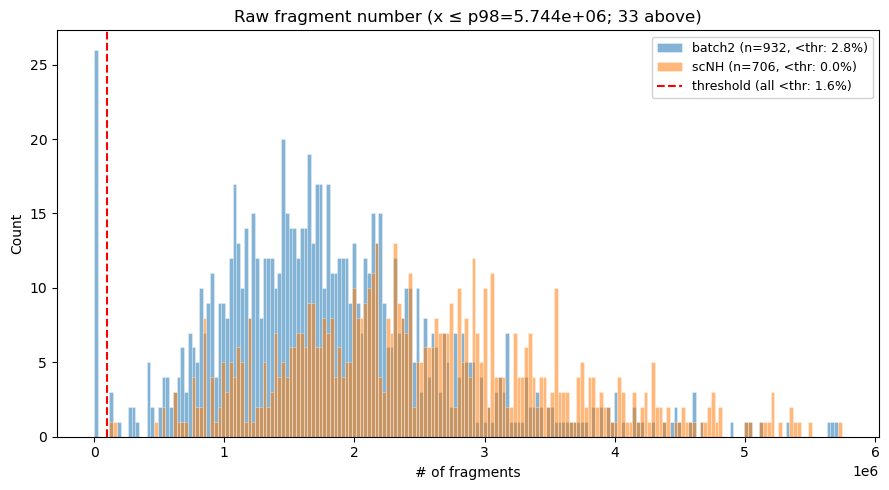

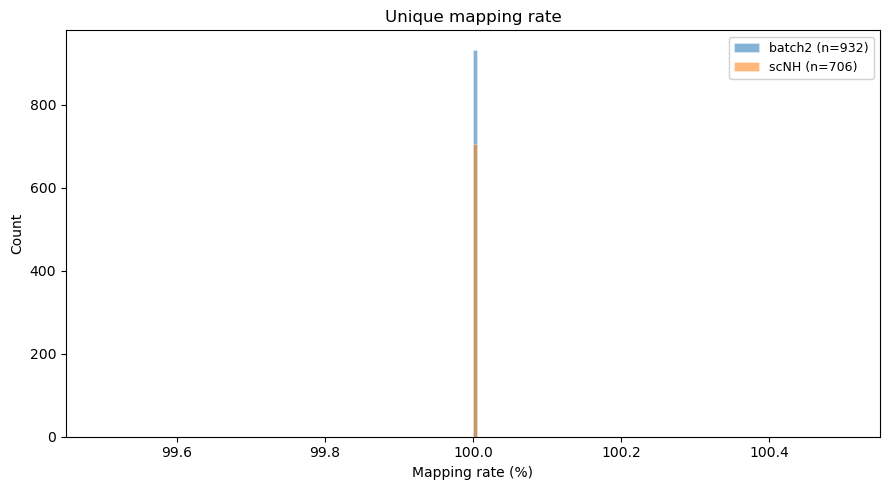

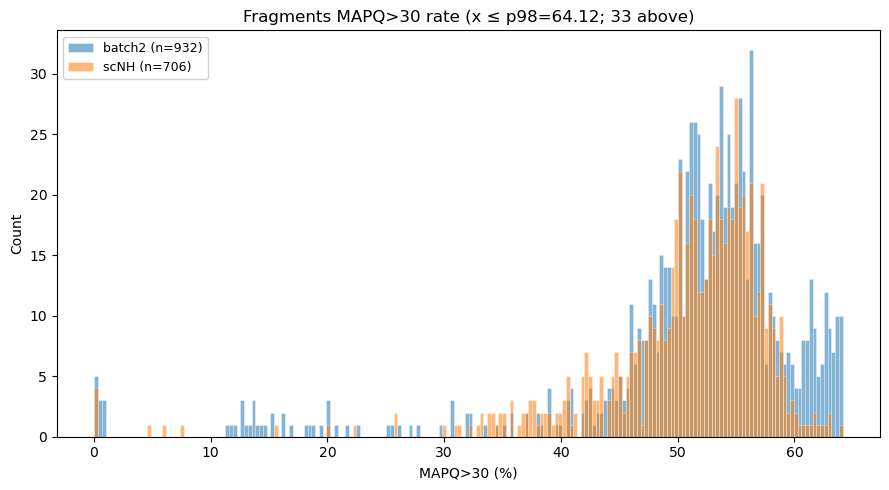

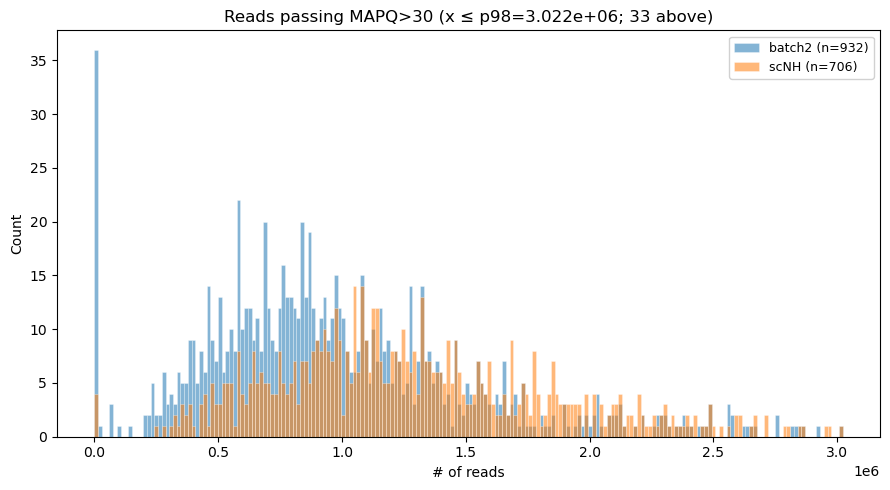

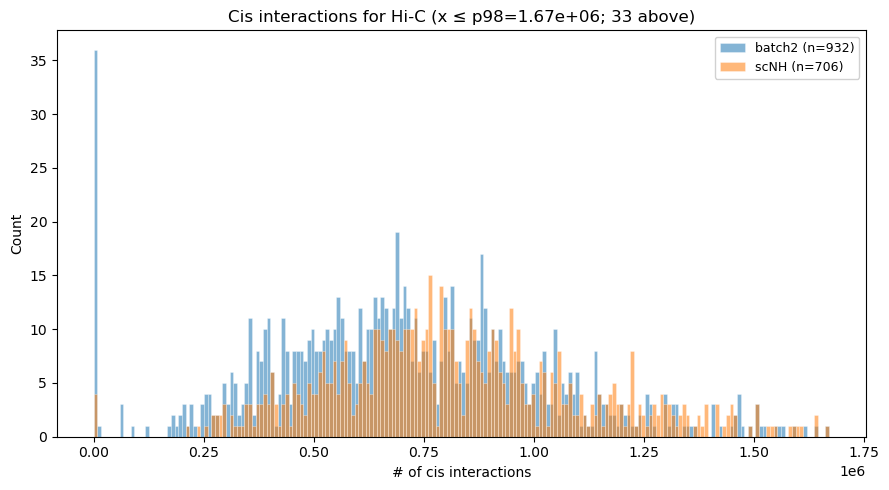

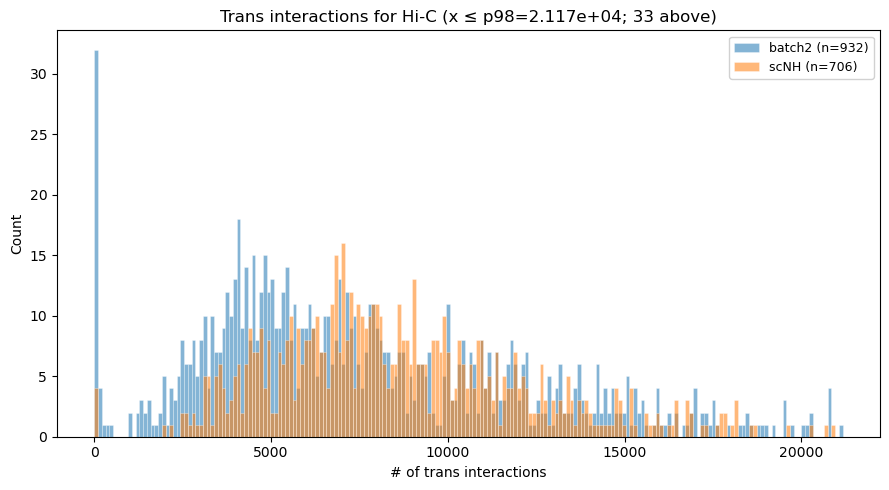

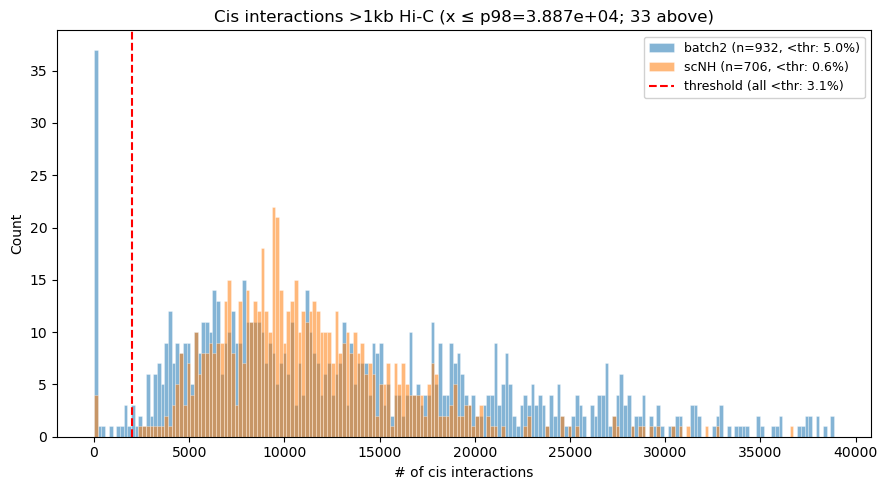

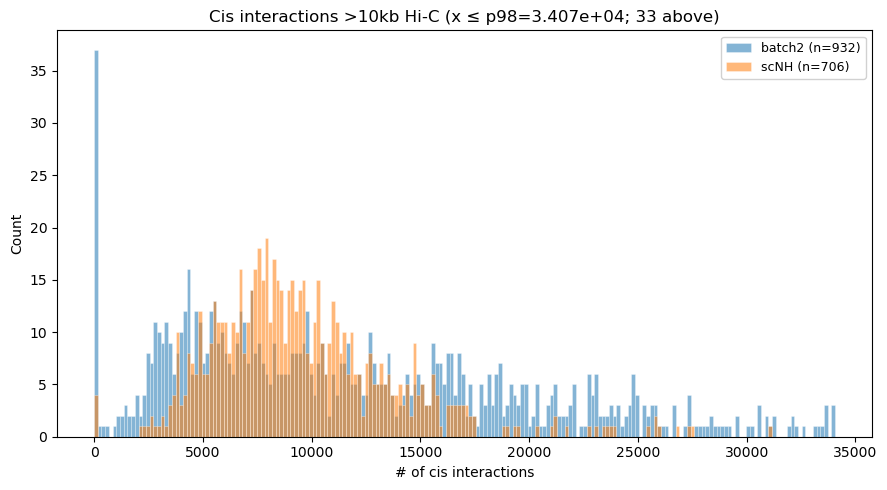

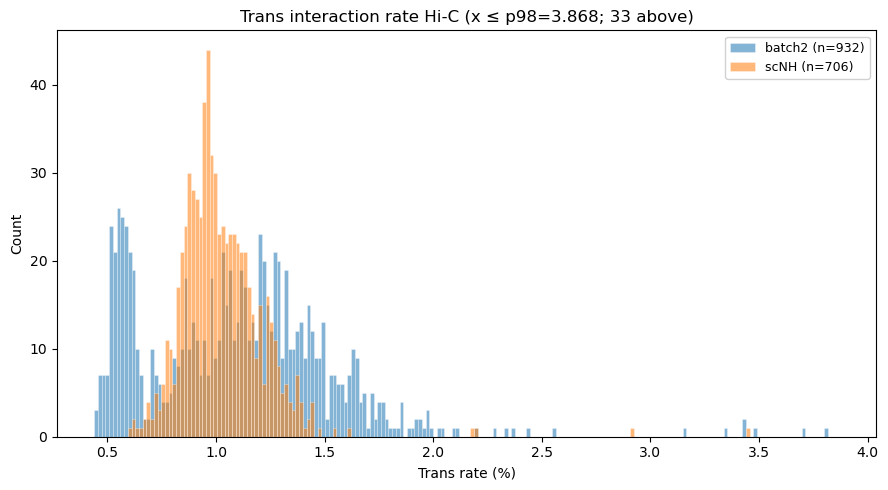

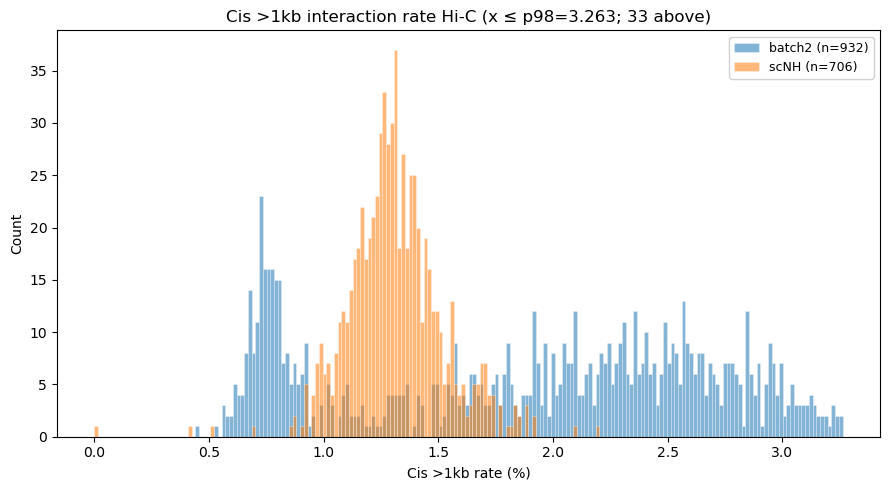

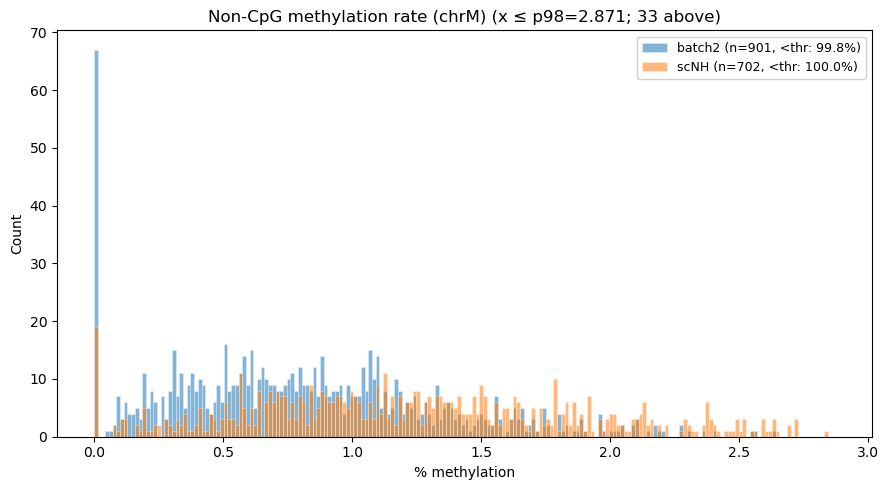

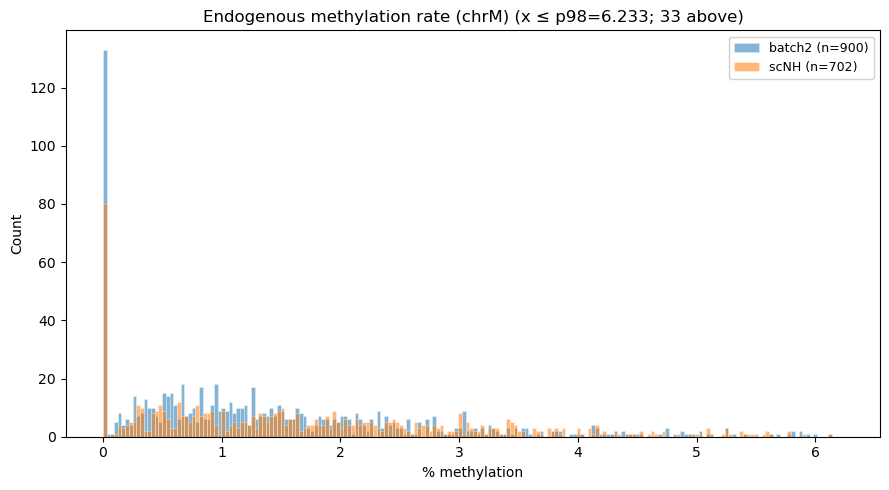

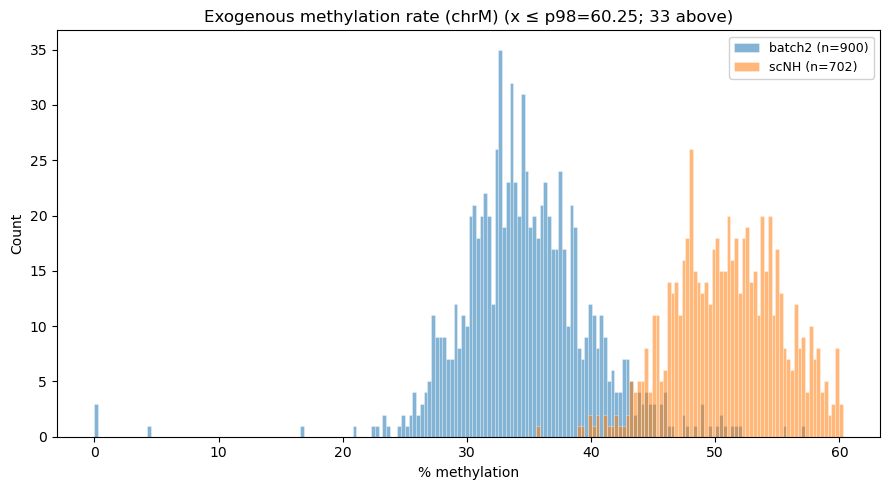

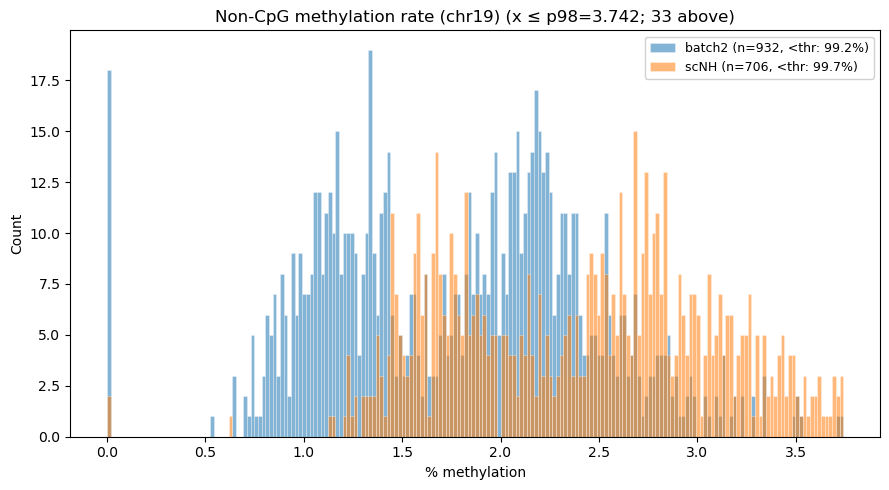

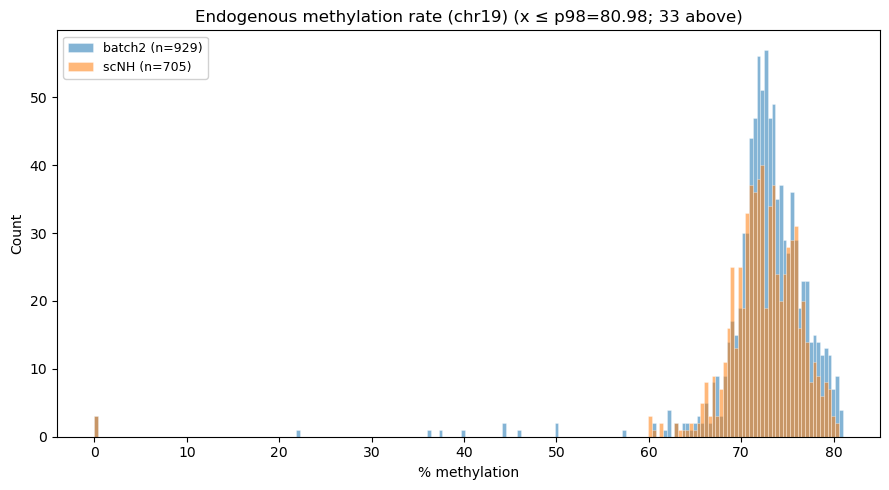

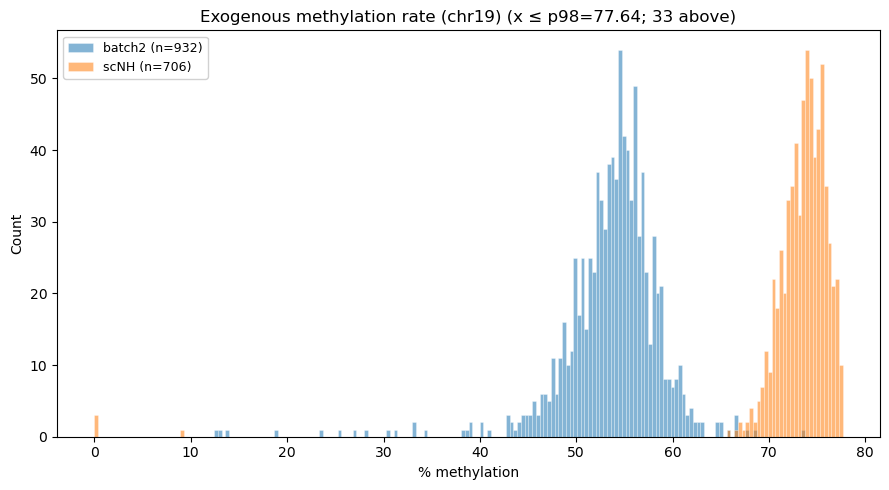

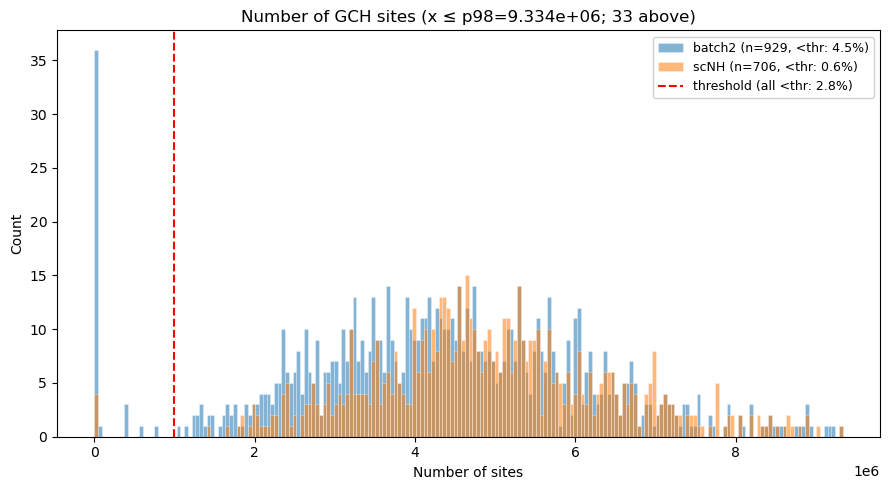

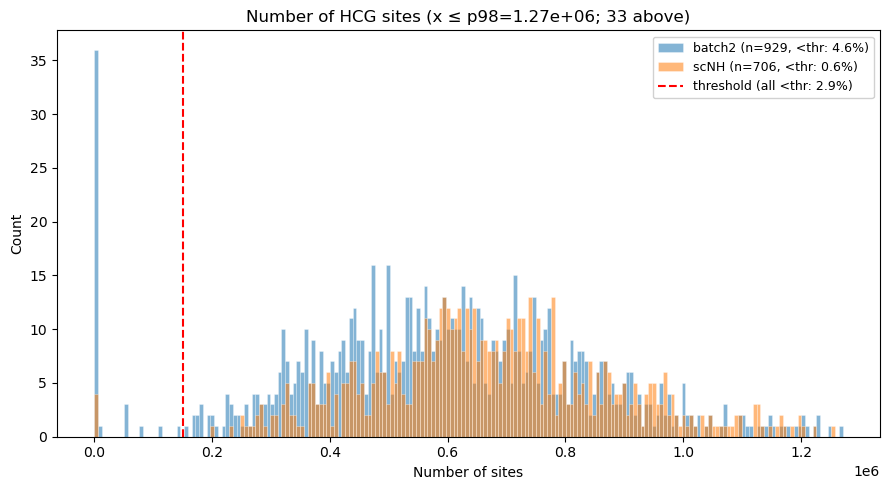

✅ Saved per-batch overlay histograms: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/figures/cortex_summary_by_batch_p99_if_outlier.pdf


In [ ]:
# Per-batch histograms: one panel per metric, batches overlaid by color
PLOT_COLUMNS = [
    ('fragnum', 'Raw fragment number', '# of fragments'),
    ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
    ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
    ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
    ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'),
    ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
    ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
    ('cis10kbnum', 'Cis interactions >10kb Hi-C', '# of cis interactions'),
    ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
    ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
    ('noncpg_chrM', 'Non-CpG methylation rate (chrM)', '% methylation'),
    ('endo_chrM', 'Endogenous methylation rate (chrM)', '% methylation'),
    ('exo_chrM', 'Exogenous methylation rate (chrM)', '% methylation'),
    ('noncpg', 'Non-CpG methylation rate (chr19)', '% methylation'),
    ('endo', 'Endogenous methylation rate (chr19)', '% methylation'),
    ('exo', 'Exogenous methylation rate (chr19)', '% methylation'),
    ('GCH', 'Number of GCH sites', 'Number of sites'),
    ('HCG', 'Number of HCG sites', 'Number of sites'),
]

METRIC_THRESHOLDS = {
    'fragnum': THRESHOLDS['fragnum_threshold'],
    'noncpg': THRESHOLDS['noncpg_threshold'],
    'noncpg_chrM': THRESHOLDS['noncpg_threshold'],
    'GCH': THRESHOLDS['GCH_threshold'],
    'HCG': THRESHOLDS['HCG_threshold'],
    'cis1kbnum': THRESHOLDS['cis1kbnum_threshold'],
}


def plot_histograms_per_batch(
    df,
    plot_columns,
    thresholds,
    batch_order=None,
    out_pdf=None,
    bins=40,
    show_inline=False,
    clip_percentile=None,
    clip_only_if_outlier=False,
):
    """One figure per metric: batches overlaid by color.

    clip_percentile: cap x-axis at this percentile (e.g. 99).
    clip_only_if_outlier: if True, only cap when any values exceed that percentile.
    """
    if 'batch' not in df.columns:
        df = df.copy()
        df['batch'] = df['prefix'].str.split('_').str[0]
    if batch_order is None:
        batch_order = sorted(df['batch'].dropna().unique())

    batch_colors = dict(
        zip(
            batch_order,
            sns.color_palette('tab10', n_colors=max(len(batch_order), 1)),
        )
    )

    pdf = PdfPages(out_pdf) if out_pdf else None
    try:
        for col, title, xlabel in plot_columns:
            fig, ax = plt.subplots(figsize=(9, 5))
            thr = thresholds.get(col)

            all_vals = df[col].dropna()
            if all_vals.empty:
                plt.close(fig)
                continue

            title_use = title
            x_hi = None
            apply_clip = False
            if clip_percentile is not None:
                x_hi = float(np.percentile(all_vals, clip_percentile))
                n_above = int((all_vals > x_hi).sum())
                apply_clip = (n_above > 0) if clip_only_if_outlier else True
                if apply_clip:
                    x_lo = all_vals.min()
                    bin_edges = np.linspace(x_lo, x_hi, bins + 1)
                    if n_above > 0:
                        title_use = (
                            f"{title} (x ≤ p{clip_percentile:.0f}={x_hi:.4g}; "
                            f"{n_above} above)"
                        )
                else:
                    x_hi = None
                    bin_edges = np.histogram_bin_edges(all_vals, bins=bins)
            else:
                bin_edges = np.histogram_bin_edges(all_vals, bins=bins)

            for batch in batch_order:
                vals_full = df.loc[df['batch'] == batch, col].dropna()
                if vals_full.empty:
                    continue
                n_total = len(vals_full)
                if thr is not None and n_total > 0:
                    pct_under = 100.0 * float((vals_full < thr).sum()) / n_total
                    label = f'{batch} (n={n_total}, <thr: {pct_under:.1f}%)'
                else:
                    label = f'{batch} (n={n_total})'

                vals = vals_full
                if apply_clip and x_hi is not None:
                    vals = vals[vals <= x_hi]
                ax.hist(
                    vals,
                    bins=bin_edges,
                    alpha=0.55,
                    color=batch_colors[batch],
                    label=label,
                    edgecolor='white',
                    linewidth=0.4,
                )

            if thr is not None and (not apply_clip or thr <= x_hi):
                all_n = len(all_vals)
                pct_under_all = 100.0 * float((all_vals < thr).sum()) / all_n if all_n else 0.0
                ax.axvline(
                    thr,
                    color='red',
                    linestyle='--',
                    linewidth=1.5,
                    label=f'threshold (all <thr: {pct_under_all:.1f}%)',
                )

            ax.set_title(title_use)
            ax.set_xlabel(xlabel)
            ax.set_ylabel('Count')
            ax.legend(loc='best', fontsize=9, framealpha=0.9)
            fig.tight_layout()

            if pdf is not None:
                pdf.savefig(fig, bbox_inches='tight')
            if show_inline:
                plt.show()
            plt.close(fig)
    finally:
        if pdf is not None:
            pdf.close()

    if out_pdf is not None:
        print(f'✅ Saved per-batch overlay histograms: {out_pdf}')


if 'batch' not in df_all_cortex.columns:
    df_all_cortex['batch'] = df_all_cortex['prefix'].str.split('_').str[0]

batch_order = sorted(df_all_cortex['batch'].unique())

# # Full range
# plot_histograms_per_batch(
#     df_all_cortex,
#     PLOT_COLUMNS,
#     METRIC_THRESHOLDS,
#     batch_order=batch_order,
#     out_pdf=OUT_FIG / 'cortex_summary_by_batch.pdf',
#     show_inline=False,
# )

# # Always cap x-axis at 99th percentile
# plot_histograms_per_batch(
#     df_all_cortex,
#     PLOT_COLUMNS,
#     METRIC_THRESHOLDS,
#     batch_order=batch_order,
#     out_pdf=OUT_FIG / 'cortex_summary_by_batch_p99.pdf',
#     clip_percentile=99,
#     clip_only_if_outlier=False,
#     show_inline=True,
# )

# Cap at p99 only when outliers exist (values above p99)
plot_histograms_per_batch(
    df_all_cortex,
    PLOT_COLUMNS,
    METRIC_THRESHOLDS,
    batch_order=batch_order,
    out_pdf=OUT_FIG / 'cortex_summary_by_batch_p99_if_outlier.pdf',
    clip_percentile=98,
    clip_only_if_outlier=True,
    show_inline=True,
    bins=200
)


In [ ]:
def plot_violins_per_batch(
    df,
    plot_columns,
    thresholds,
    batch_order=None,
    out_pdf=None,
    show_inline=False,
    clip_percentile=None,
    clip_only_if_outlier=False,
):
    """One figure per metric: violin plot across batches."""

    if 'batch' not in df.columns:
        df = df.copy()
        df['batch'] = df['prefix'].str.split('_').str[0]

    if batch_order is None:
        batch_order = sorted(df['batch'].dropna().unique())

    pdf = PdfPages(out_pdf) if out_pdf else None

    try:
        for col, title, ylabel in plot_columns:
            if col not in df.columns:
                continue

            plot_df = df[['batch', col]].dropna().copy()
            plot_df = plot_df[plot_df['batch'].isin(batch_order)]

            if plot_df.empty:
                continue

            thr = thresholds.get(col)
            title_use = title

            if clip_percentile is not None:
                x_hi = float(np.percentile(plot_df[col], clip_percentile))
                n_above = int((plot_df[col] > x_hi).sum())

                apply_clip = (n_above > 0) if clip_only_if_outlier else True

                if apply_clip:
                    plot_df = plot_df[plot_df[col] <= x_hi]
                    title_use = (
                        f"{title} (≤ p{clip_percentile:.0f}={x_hi:.4g}; "
                        f"{n_above} above)"
                    )

            fig, ax = plt.subplots(figsize=(10, 5))

            sns.violinplot(
                data=plot_df,
                x='batch',
                y=col,
                order=batch_order,
                inner='box',
                cut=0,
                linewidth=1,
                ax=ax,
            )

            sns.stripplot(
                data=plot_df,
                x='batch',
                y=col,
                order=batch_order,
                color='black',
                size=1.5,
                alpha=0.25,
                jitter=0.25,
                ax=ax,
            )

            if thr is not None:
                all_vals = df[col].dropna()
                pct_under_all = 100.0 * (all_vals < thr).sum() / len(all_vals)

                ax.axhline(
                    thr,
                    color='red',
                    linestyle='--',
                    linewidth=1.5,
                    label=f'threshold (all <thr: {pct_under_all:.1f}%)',
                )
                ax.legend(loc='best', fontsize=9)

            ax.set_title(title_use)
            ax.set_xlabel('Batch')
            ax.set_ylabel(ylabel)
            ax.tick_params(axis='x', rotation=45)
            fig.tight_layout()

            if pdf is not None:
                pdf.savefig(fig, bbox_inches='tight')

            if show_inline:
                plt.show()

            plt.close(fig)

    finally:
        if pdf is not None:
            pdf.close()

    if out_pdf is not None:
        print(f'✅ Saved per-batch violin plots: {out_pdf}')

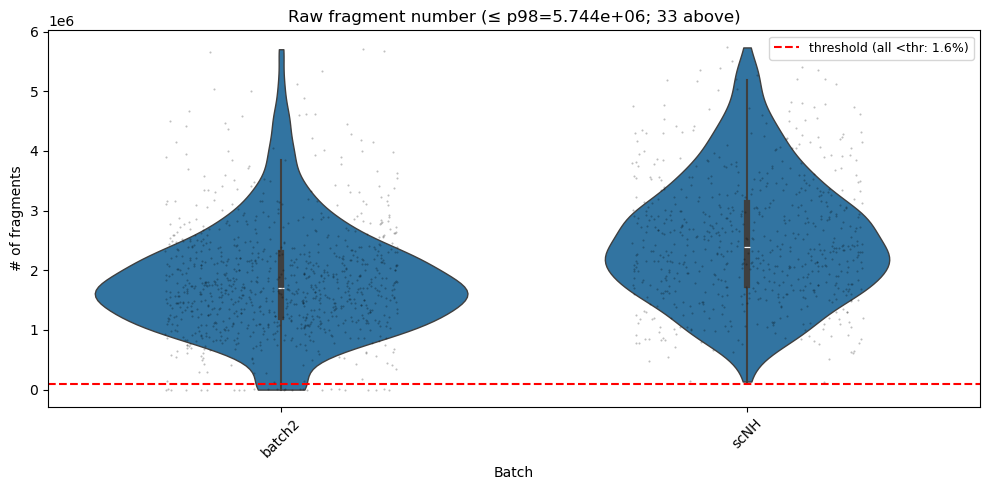

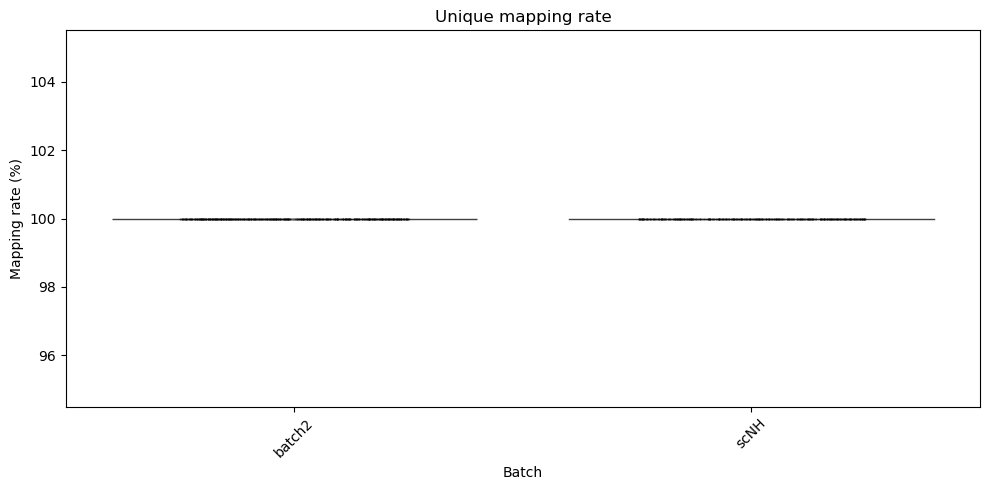

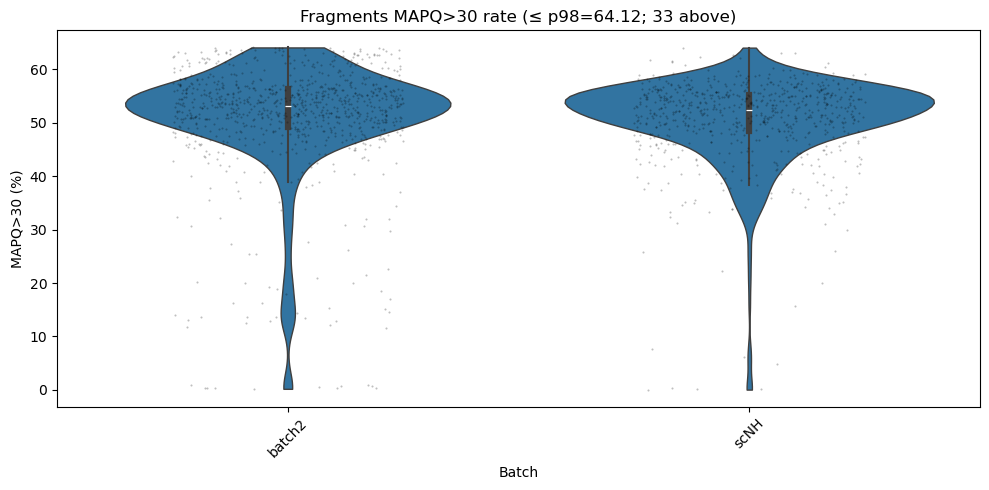

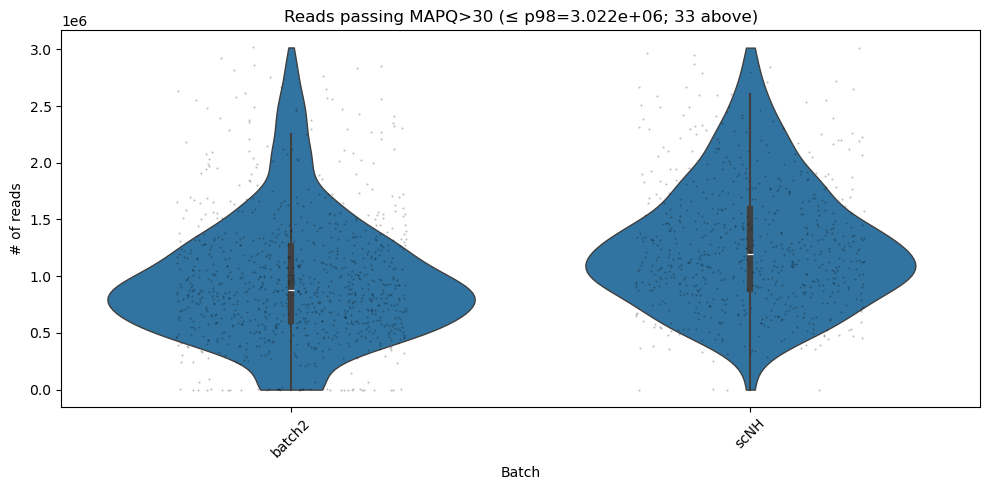

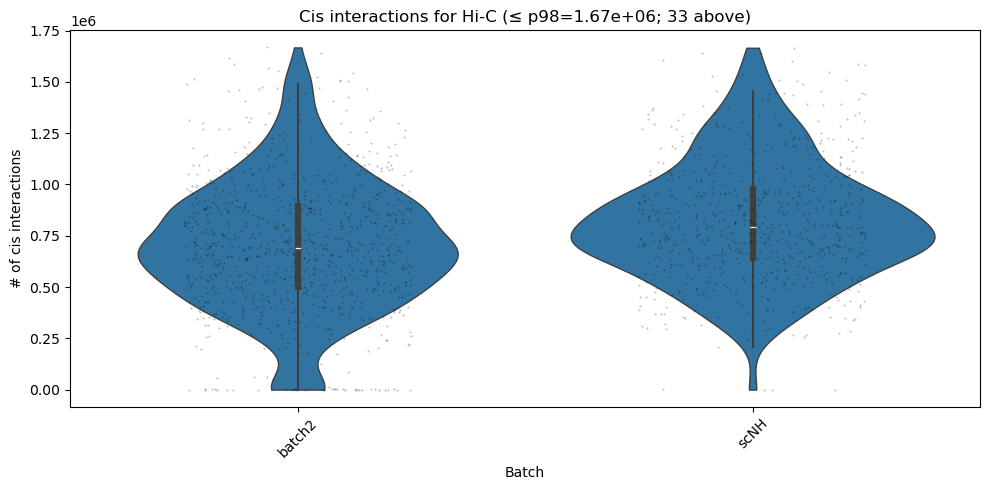

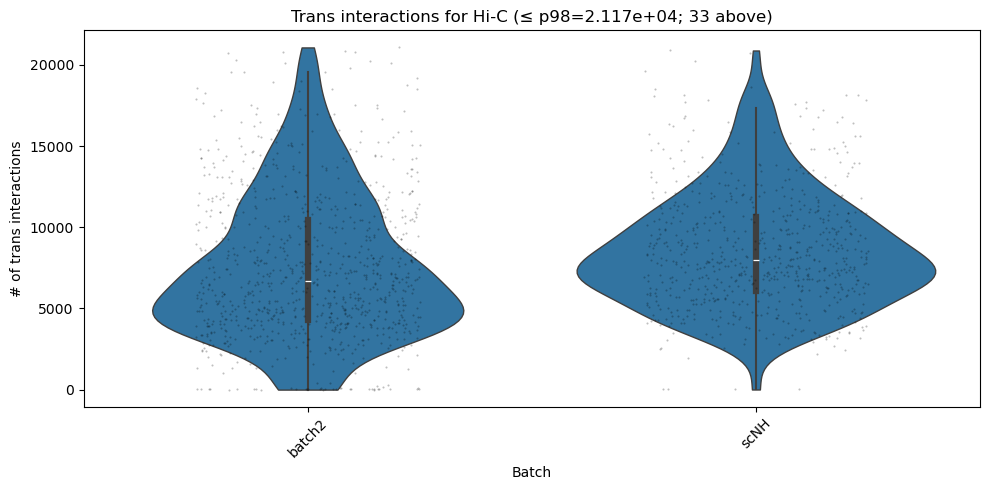

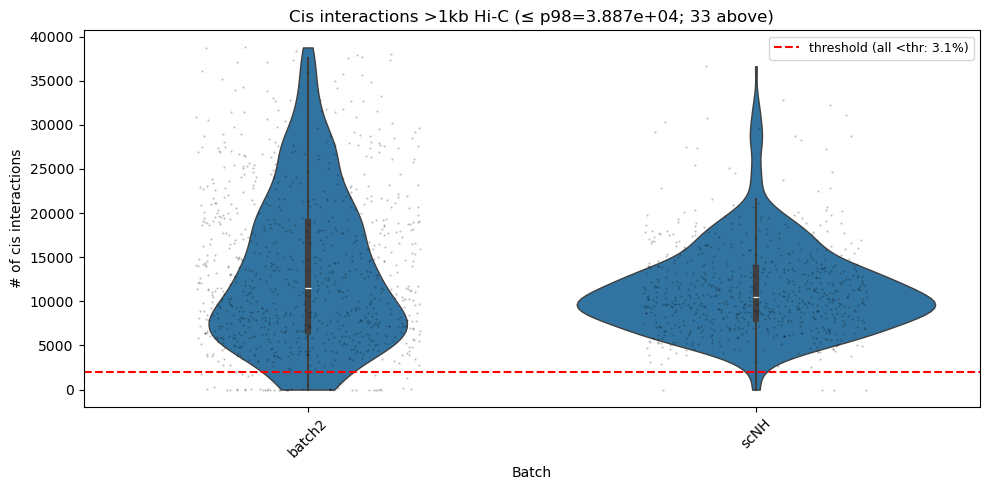

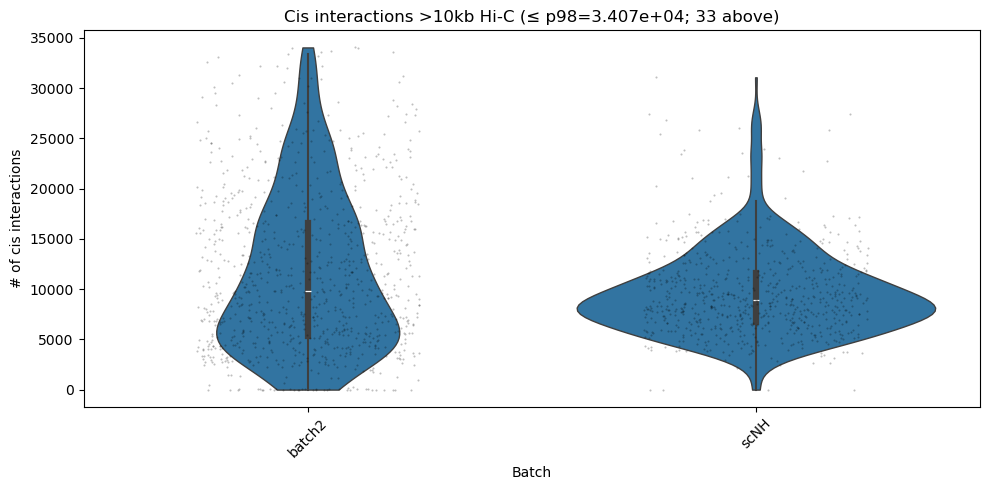

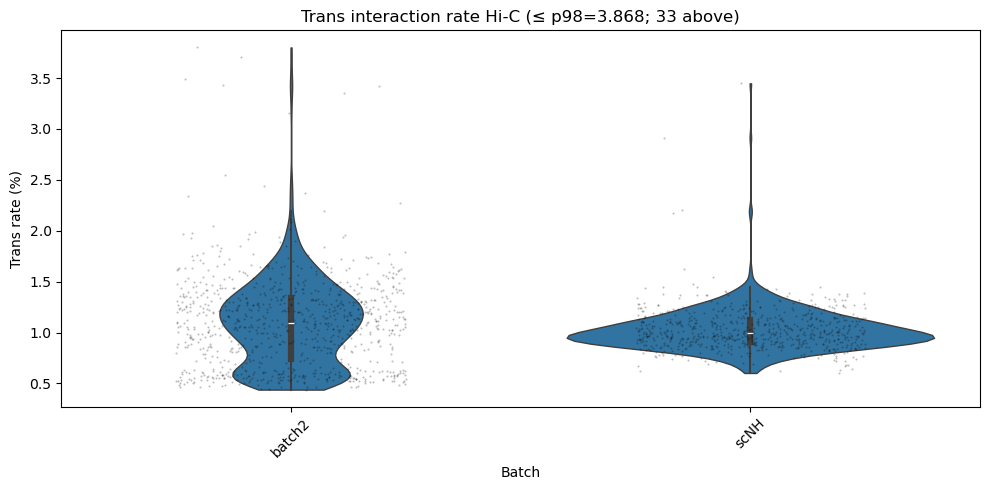

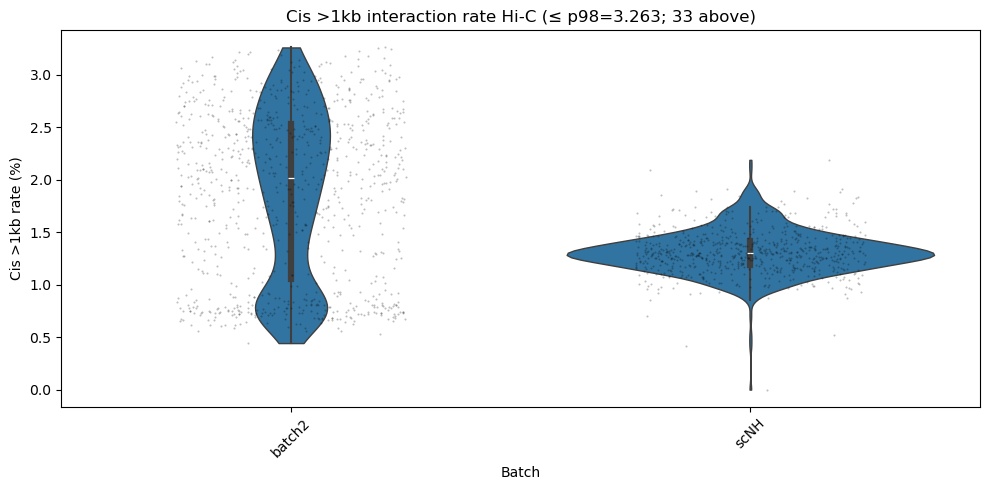

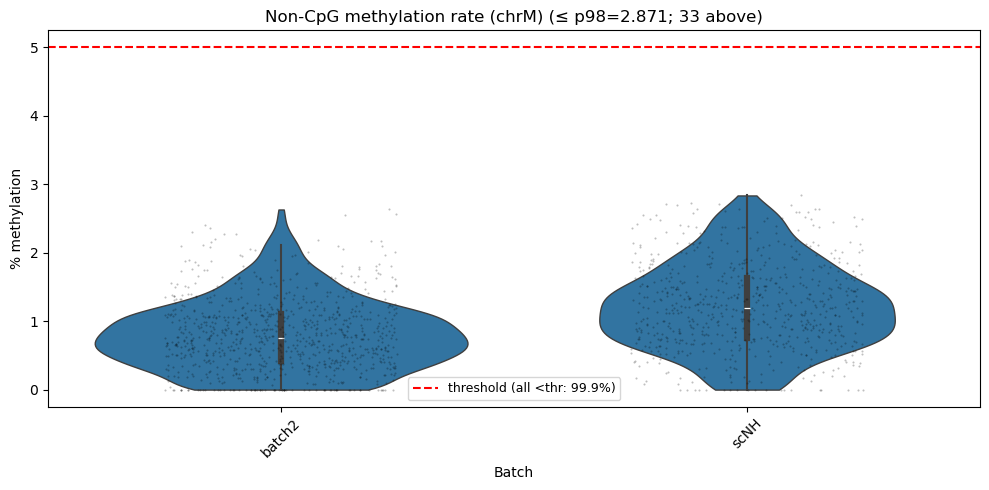

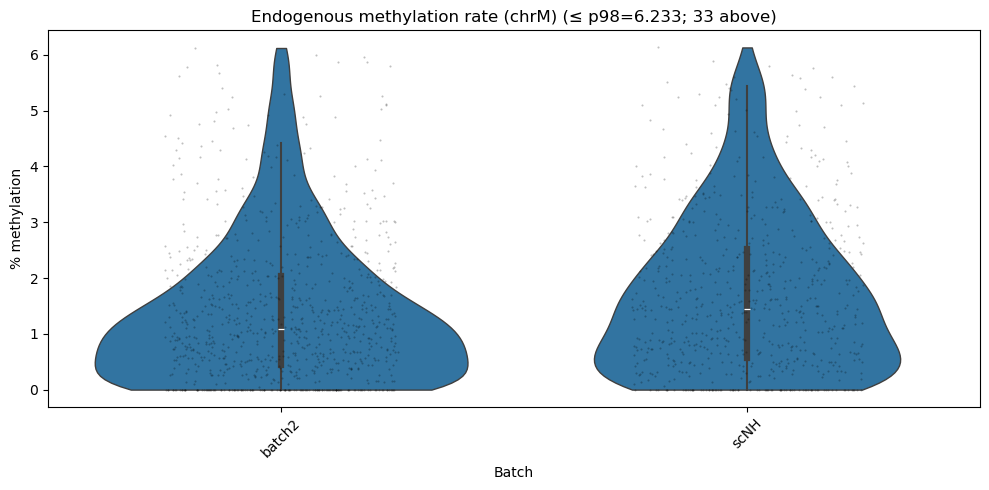

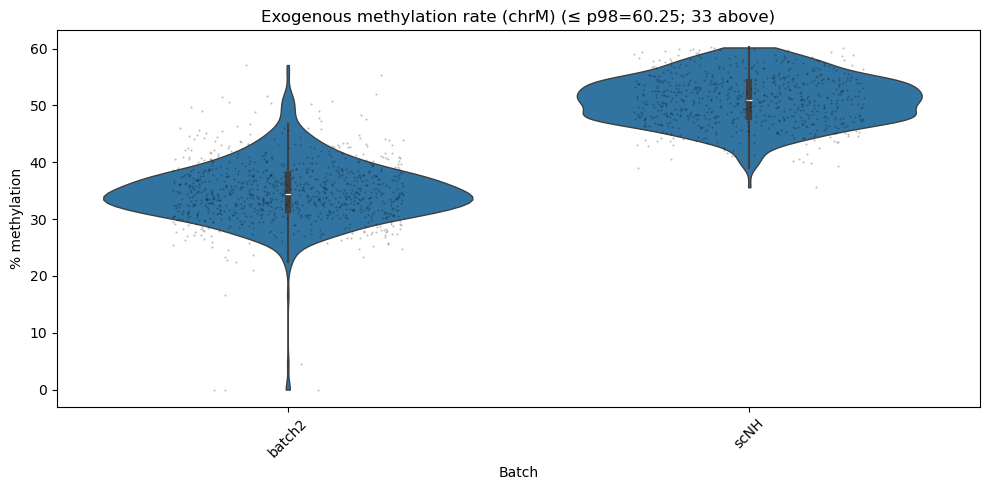

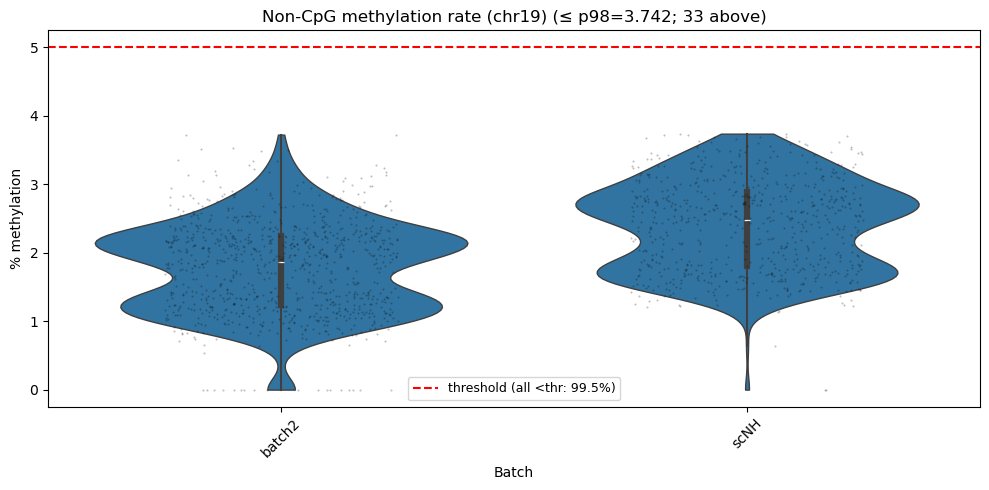

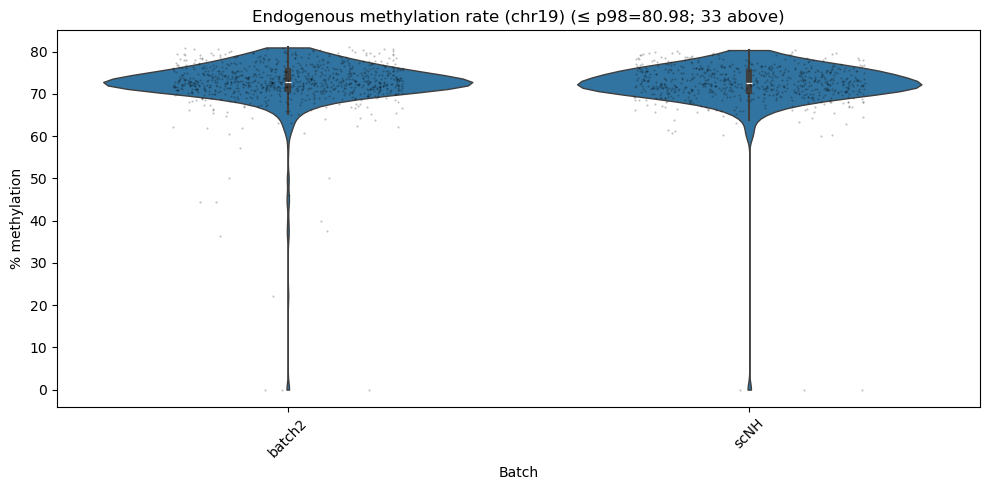

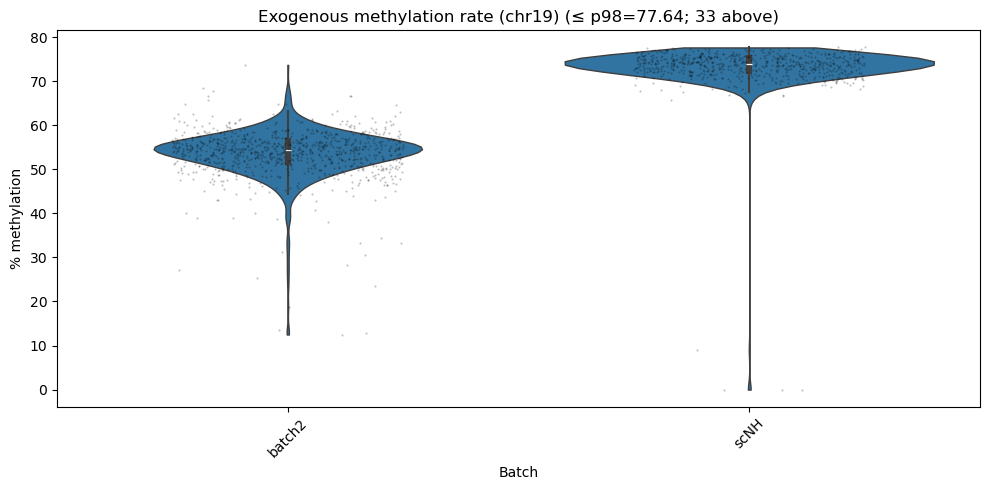

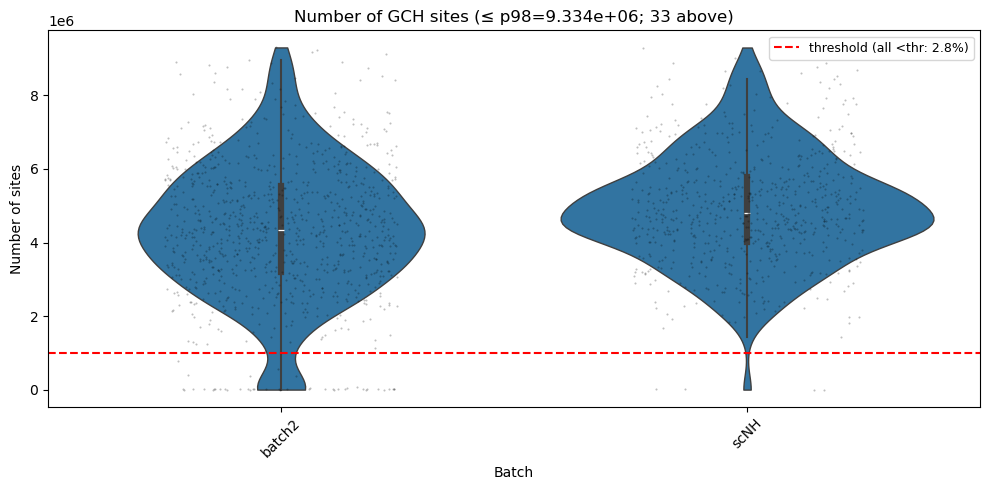

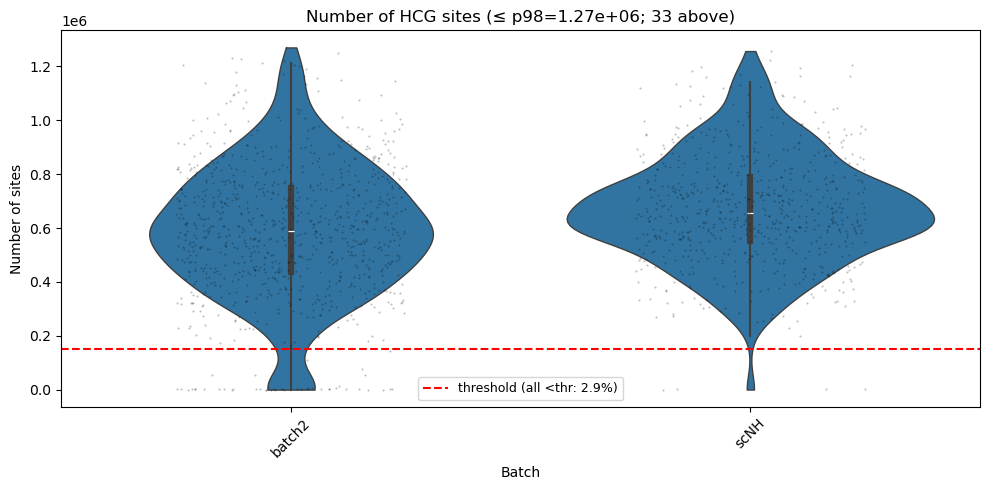

✅ Saved per-batch violin plots: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/figures/cortex_summary_by_batch_violin_p98_if_outlier.pdf


In [ ]:
plot_violins_per_batch(
    df_all_cortex,
    PLOT_COLUMNS,
    METRIC_THRESHOLDS,
    batch_order=batch_order,
    out_pdf=OUT_FIG / 'cortex_summary_by_batch_violin_p98_if_outlier.pdf',
    clip_percentile=98,
    clip_only_if_outlier=True,
    show_inline=True,
)

In [ ]:
# Publication-style violin: non-CpG methylation by batch
sns.set_context('paper', font_scale=1.4)
sns.set_style('whitegrid')
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

plot_df = df_all_cortex.dropna(subset=['noncpg']).copy()
batch_order = sorted(plot_df['batch'].unique())

plt.figure(figsize=(8, 6))
ax = sns.violinplot(data=plot_df, x='batch', y='noncpg', order=batch_order, inner='box', cut=0)
ax.set_xlabel('')
ax.set_ylabel('Non-CpG methylation rate (%)')
ax.set_title('Non-CpG methylation by batch')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(OUT_FIG / 'noncpg_by_batch.pdf', dpi=300)
plt.savefig(OUT_FIG / 'noncpg_by_batch.png', dpi=300)
plt.show()

## Cell × bin methylation matrices (250 kb)

Build dense matrices from `08.methylation_snakemake/*.{GCH,HCG}.250kb_methylation.txt.gz`:
- **rows** = cells
- **columns** = `bin_id` (250 kb bins)
- **values** = `methylation_level`

Outputs under `QC/` (gzip TSV). Set `USE_QC_PASSED_ONLY = True` to restrict to `cortex_passed.txt`.

In [ ]:
METH_BIN_DIR = WORKDIR / '08.methylation_snakemake'
BIN_LABEL = '100kb'
OUT_MATRIX = OUT_QC / 'methylation_matrices'
OUT_MATRIX.mkdir(exist_ok=True)

# Set True to use only QC-passed cells (from cortex_passed.txt)
USE_QC_PASSED_ONLY = False


def build_methylation_matrix(context, bin_label=BIN_LABEL, meth_dir=METH_BIN_DIR, cells=None):
    """Return cells × bins matrix of methylation_level."""
    pattern = f'*.{context}.{bin_label}_methylation.txt.gz'
    files = sorted(meth_dir.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No files matching {pattern} in {meth_dir}')

    if cells is not None:
        cells = set(cells)
        files = [f for f in files if _cell_from_methylation_path(f, context, bin_label) in cells]

    rows = []
    for path in tqdm(files, desc=f'{context} {bin_label}'):
        cell = _cell_from_methylation_path(path, context, bin_label)
        df = pd.read_csv(path, sep='\t', usecols=['bin_id', 'methylation_level'])
        rows.append(df.set_index('bin_id')['methylation_level'].rename(cell))

    mat = pd.concat(rows, axis=1).T
    mat.index.name = 'cell'
    return mat


def _cell_from_methylation_path(path, context, bin_label):
    suffix = f'.{context}.{bin_label}_methylation.txt.gz'
    return Path(path).name[: -len(suffix)]


def save_bin_coords(meth_dir, bin_label, out_path):
    """Save bin coordinates once (same across cells)."""
    ref = next(meth_dir.glob(f'*.GCH.{bin_label}_methylation.txt.gz'))
    coords = pd.read_csv(ref, sep='\t', usecols=['bin_id', 'chr', 'start', 'end'])
    coords.to_csv(out_path, sep='\t', index=False)
    return coords


cells_filter = None
if USE_QC_PASSED_ONLY:
    passed_path = OUT_QC / 'cortex_passed.txt'
    if passed_path.exists():
        cells_filter = pd.read_csv(passed_path, header=None)[0].tolist()
        print(f'Filtering to {len(cells_filter)} QC-passed cells')
    else:
        print('⚠️ cortex_passed.txt not found; using all cells')

bin_coords_path = OUT_MATRIX / f'bins_{BIN_LABEL}.tsv'
if not bin_coords_path.exists():
    save_bin_coords(METH_BIN_DIR, BIN_LABEL, bin_coords_path)
    print(f'Saved bin coordinates: {bin_coords_path}')

for context in ('GCH', 'HCG'):
    mat = build_methylation_matrix(context, cells=cells_filter)
    out_file = OUT_MATRIX / f'methylation_matrix_{context}_{BIN_LABEL}.tsv.gz'
    mat.to_csv(out_file, sep='\t', compression='gzip')
    print(
        f'✅ {context}: {mat.shape[0]} cells × {mat.shape[1]} bins → {out_file} '
        f'({out_file.stat().st_size / 1e6:.1f} MB)'
    )
    display(mat.iloc[:3, :5])


In [ ]:
METH_BIN_DIR = WORKDIR / '08.methylation_snakemake'
BIN_LABEL = '250kb'
OUT_MATRIX = OUT_QC / 'methylation_matrices'
OUT_MATRIX.mkdir(exist_ok=True)

# Set True to use only QC-passed cells (from cortex_passed.txt)
USE_QC_PASSED_ONLY = False


def build_methylation_matrix(context, bin_label=BIN_LABEL, meth_dir=METH_BIN_DIR, cells=None):
    """Return cells × bins matrix of methylation_level."""
    pattern = f'*.{context}.{bin_label}_methylation.txt.gz'
    files = sorted(meth_dir.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No files matching {pattern} in {meth_dir}')

    if cells is not None:
        cells = set(cells)
        files = [f for f in files if _cell_from_methylation_path(f, context, bin_label) in cells]

    rows = []
    for path in tqdm(files, desc=f'{context} {bin_label}'):
        cell = _cell_from_methylation_path(path, context, bin_label)
        df = pd.read_csv(path, sep='\t', usecols=['bin_id', 'methylation_level'])
        rows.append(df.set_index('bin_id')['methylation_level'].rename(cell))

    mat = pd.concat(rows, axis=1).T
    mat.index.name = 'cell'
    return mat


def _cell_from_methylation_path(path, context, bin_label):
    suffix = f'.{context}.{bin_label}_methylation.txt.gz'
    return Path(path).name[: -len(suffix)]


def save_bin_coords(meth_dir, bin_label, out_path):
    """Save bin coordinates once (same across cells)."""
    ref = next(meth_dir.glob(f'*.GCH.{bin_label}_methylation.txt.gz'))
    coords = pd.read_csv(ref, sep='\t', usecols=['bin_id', 'chr', 'start', 'end'])
    coords.to_csv(out_path, sep='\t', index=False)
    return coords


cells_filter = None
if USE_QC_PASSED_ONLY:
    passed_path = OUT_QC / 'cortex_passed.txt'
    if passed_path.exists():
        cells_filter = pd.read_csv(passed_path, header=None)[0].tolist()
        print(f'Filtering to {len(cells_filter)} QC-passed cells')
    else:
        print('⚠️ cortex_passed.txt not found; using all cells')

bin_coords_path = OUT_MATRIX / f'bins_{BIN_LABEL}.tsv'
if not bin_coords_path.exists():
    save_bin_coords(METH_BIN_DIR, BIN_LABEL, bin_coords_path)
    print(f'Saved bin coordinates: {bin_coords_path}')

for context in ('GCH', 'HCG'):
    mat = build_methylation_matrix(context, cells=cells_filter)
    out_file = OUT_MATRIX / f'methylation_matrix_{context}_{BIN_LABEL}.tsv.gz'
    mat.to_csv(out_file, sep='\t', compression='gzip')
    print(
        f'✅ {context}: {mat.shape[0]} cells × {mat.shape[1]} bins → {out_file} '
        f'({out_file.stat().st_size / 1e6:.1f} MB)'
    )
    display(mat.iloc[:3, :5])
